# CRKPINN training -- GRI-30 CH4/air

Physics-informed surrogate for combustion reaction kinetics, following
Zhang, Zhang & Wang (2024) "CRK-PINN" as closely as practical. Predicts the
next state (T, Y) directly given the current state, T0, P, and a time step
dt -- see `models/CRKPINN.py` for the architecture and normalization.

Loss terms are modular (`utils/losses.py`): L_data is always on; L_mole,
L_element, L_enthalpy, L_arrhenius can each be toggled via their LAMBDA_*
weight. Start with small weights when turning a new term on -- L_mole at
weight 1e2 caused training to blow up before; 0.1 was stable.

Run top to bottom. Training continues to accumulate into train_losses/
val_losses across re-runs of the training cell (doesn't reset model/opt),
so you can extend training or add loss terms incrementally without
restarting from scratch.

In [1]:
import sys
sys.path.append("..")

import os
import numpy as np
import pandas as pd
import torch
import cantera as ct
import matplotlib.pyplot as plt

from models.CRKPINN import CRKPINN
from models.GlobalArrheniusRate import GlobalArrheniusRate
from utils.physics import build_physics_utils
from utils.losses import loss_data, loss_mole, loss_element, loss_enthalpy, loss_arrhenius

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Load data and mechanism

In [2]:
df = pd.read_csv("../data/raw/gri30_ch4_air_trajectories.csv")
species_cols = [c.replace("Y_", "") for c in df.columns if c.startswith("Y_")]
gas = ct.Solution("gri30.yaml")
mw = np.array([gas.molecular_weights[gas.species_index(s)] for s in species_cols])

print(f"{len(df)} rows, {df['traj_idx'].nunique()} trajectories")
print(f"ignited fraction: {df.groupby('traj_idx')['ignited'].first().mean():.2%}")

physics = build_physics_utils(gas, species_cols, device)

98100 rows, 981 trajectories
ignited fraction: 100.00%


/home/MatsAlbert/miniconda3/envs/TEP4541/lib/python3.12/site-packages/torch/cuda/__init__.py:827: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


## Split by traj

In [3]:
traj_ids = df["traj_idx"].unique()
rng = np.random.default_rng(0)
rng.shuffle(traj_ids)
n_val = int(0.2 * len(traj_ids))
val_ids, train_ids = set(traj_ids[:n_val]), set(traj_ids[n_val:])

# Buld t, dt pairs

In [4]:
N_IDT = 5.0
PAIRS_VERSION = "v2_with_rho"
TRAIN_PAIRS_CACHE = f"../data/processed/train_pairs_{PAIRS_VERSION}.parquet"
VAL_PAIRS_CACHE = f"../data/processed/val_pairs_{PAIRS_VERSION}.parquet"

def build_pairs(d):
    d = d.sort_values(["traj_idx", "t"]).reset_index(drop=True)
    shift_cols = ["t", "T", "rho"] + [f"Y_{s}" for s in species_cols]
    shifted = d.groupby("traj_idx")[shift_cols].shift(-1)
    valid = shifted["T"].notna()

    keep_cols = ["T", "T0", "P", "rho", "t", "t_ign"] + [f"Y_{s}" for s in species_cols]
    out = d.loc[valid, keep_cols].reset_index(drop=True)

    extra = pd.DataFrame({
        "T_next": shifted.loc[valid, "T"].reset_index(drop=True),
        "dt": (shifted.loc[valid, "t"] - d.loc[valid, "t"]).reset_index(drop=True),
        **{f"Y_{s}_next": shifted.loc[valid, f"Y_{s}"].reset_index(drop=True) for s in species_cols},
    })
    out = pd.concat([out, extra], axis=1)
    out["t_end"] = N_IDT * out["t_ign"]
    return out

if os.path.exists(TRAIN_PAIRS_CACHE) and os.path.exists(VAL_PAIRS_CACHE):
    print("Loading cached pairs...")
    train_pairs = pd.read_parquet(TRAIN_PAIRS_CACHE)
    val_pairs = pd.read_parquet(VAL_PAIRS_CACHE)
else:
    print("Building pairs...")
    train_pairs = build_pairs(df[df["traj_idx"].isin(train_ids)])
    val_pairs = build_pairs(df[df["traj_idx"].isin(val_ids)])
    os.makedirs(os.path.dirname(TRAIN_PAIRS_CACHE), exist_ok=True)
    train_pairs.to_parquet(TRAIN_PAIRS_CACHE)
    val_pairs.to_parquet(VAL_PAIRS_CACHE)
    print("Saved pairs to cache.")

print(f"{len(train_pairs)} train pairs, {len(val_pairs)} val pairs")

Loading cached pairs...
77715 train pairs, 19404 val pairs


In [6]:
def to_tensors(d):
    T = torch.tensor(d["T"].to_numpy(), dtype=torch.float32, device=device)
    T_next = torch.tensor(d["T_next"].to_numpy(), dtype=torch.float32, device=device)
    T0 = torch.tensor(d["T0"].to_numpy(), dtype=torch.float32, device=device)
    P = torch.tensor(d["P"].to_numpy(), dtype=torch.float32, device=device)
    rho = torch.tensor(d["rho"].to_numpy(), dtype=torch.float32, device=device)
    dt = torch.tensor(d["dt"].to_numpy(), dtype=torch.float32, device=device)
    t_end = torch.tensor(d["t_end"].to_numpy(), dtype=torch.float32, device=device)
    Y = torch.tensor(d[[f"Y_{s}" for s in species_cols]].to_numpy(), dtype=torch.float32, device=device)
    Y_next = torch.tensor(d[[f"Y_{s}_next" for s in species_cols]].to_numpy(), dtype=torch.float32, device=device)
    return T, Y, T0, P, rho, dt, t_end, T_next, Y_next


T_tr, Y_tr, T0_tr, P_tr, rho_tr, dt_tr, tend_tr, T_next_tr, Y_next_tr = to_tensors(train_pairs)
T_va, Y_va, T0_va, P_va, rho_va, dt_va, tend_va, T_next_va, Y_next_va = to_tensors(val_pairs)

# Model + normalization stats

In [13]:
model = CRKPINN(n_species=len(species_cols)).to(device)

Y_MIN = model.Y_MIN
logY_all = torch.log(torch.clamp(torch.cat([Y_tr, Y_next_tr], dim=0), min=Y_MIN))
logP_all = torch.log(torch.clamp(P_tr, min=1e-6))
tprime_raw = dt_tr / torch.clamp(tend_tr, min=1e-12)

model.set_norm_stats(
    logY_mean=logY_all.mean(dim=0), logY_std=logY_all.std(dim=0),
    T_mean=torch.cat([T_tr, T_next_tr]).mean(), T_std=torch.cat([T_tr, T_next_tr]).std(),
    T0_mean=T0_tr.mean(), T0_std=T0_tr.std(),
    logP_mean=logP_all.mean(), logP_std=logP_all.std(),
    tprime_mean=tprime_raw.mean(), tprime_std=tprime_raw.std(),
)

# Auxiliary global-reaction module, only used if LAMBDA_ARRHENIUS > 0
arrhenius_module = GlobalArrheniusRate(n_species=len(species_cols), molecular_weights=mw).to(device)

opt = torch.optim.Adam(list(model.parameters()) + list(arrhenius_module.parameters()), lr=1e-5)

# ---- Loss weights -- start conservative, raise gradually once stable ----
LAMBDA_DATA = 1.0
LAMBDA_MOLE = 0.1
LAMBDA_ELEMENT = 0.0004
LAMBDA_ENTHALPY = 0.0
LAMBDA_ARRHENIUS = 0.00001

train_losses, val_losses, val_epochs = [], [], []

# Sanity check

In [8]:
with torch.no_grad():
    T_check, Y_check, info_check = model(
        T_tr[:1024], Y_tr[:1024], T0_tr[:1024], P_tr[:1024], dt_tr[:1024], tend_tr[:1024]
    )
    print("T_next_pred has nan:", torch.isnan(T_check).any().item())
    print("Y_next_pred has nan:", torch.isnan(Y_check).any().item())
    print("T_next_pred range:", T_check.min().item(), T_check.max().item())

T_next_pred has nan: False
Y_next_pred has nan: False
T_next_pred range: 1986.3082275390625 2530.791259765625


# Train

In [14]:
n_epochs = 300
batch_size = 1024
n_train = T_tr.shape[0]

for epoch in range(n_epochs):
    perm = torch.randperm(n_train, device=device)
    total_loss = 0.0
    for i in range(0, n_train, batch_size):
        idx = perm[i:i + batch_size]

        T_next_pred, Y_next_pred, info = model(
            T_tr[idx], Y_tr[idx], T0_tr[idx], P_tr[idx], dt_tr[idx], tend_tr[idx]
        )

        L_data = loss_data(model, info, T_next_tr[idx], Y_next_tr[idx])
        L_mole = loss_mole(Y_next_pred) if LAMBDA_MOLE > 0 else torch.tensor(0.0, device=device)
        L_element = loss_element(physics.element_mass_fractions, Y_tr[idx], Y_next_pred) if LAMBDA_ELEMENT > 0 else torch.tensor(0.0, device=device)
        L_enthalpy = loss_enthalpy(physics.mixture_specific_enthalpy, T_tr[idx], Y_tr[idx], T_next_pred, Y_next_pred) if LAMBDA_ENTHALPY > 0 else torch.tensor(0.0, device=device)
        L_arrhenius = loss_arrhenius(model, arrhenius_module, T_tr[idx], Y_tr[idx], T0_tr[idx], P_tr[idx], dt_tr[idx], tend_tr[idx], rho_tr[idx]) if LAMBDA_ARRHENIUS > 0 else torch.tensor(0.0, device=device)

        loss = (LAMBDA_DATA * L_data
                + LAMBDA_MOLE * L_mole
                + LAMBDA_ELEMENT * L_element 
                # + LAMBDA_ENTHALPY * L_enthalpy
                + LAMBDA_ARRHENIUS * L_arrhenius
                )

        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        total_loss += loss.item() * len(idx)

    train_losses.append(total_loss / n_train)

    if epoch % 10 == 0:
        with torch.no_grad():
            T_next_pred_v, Y_next_pred_v, info_v = model(T_va, Y_va, T0_va, P_va, dt_va, tend_va)
            val_loss = loss_data(model, info_v, T_next_va, Y_next_va)
        val_losses.append(val_loss.item())
        val_epochs.append(len(train_losses) - 1)
        print(f"epoch {len(train_losses)-1:4d}  train {total_loss/n_train:.4f}  val(data only) {val_loss.item():.4f}")

epoch    0  train 1.8387  val(data only) 1.6980
epoch   10  train 0.5769  val(data only) 0.6023
epoch   20  train 0.3610  val(data only) 0.3871
epoch   30  train 0.2706  val(data only) 0.2900
epoch   40  train 0.2240  val(data only) 0.2412
epoch   50  train 0.2022  val(data only) 0.2187
epoch   60  train 0.1873  val(data only) 0.2035
epoch   70  train 0.1742  val(data only) 0.1897
epoch   80  train 0.1631  val(data only) 0.1780
epoch   90  train 0.1537  val(data only) 0.1683
epoch  100  train 0.1454  val(data only) 0.1595
epoch  110  train 0.1379  val(data only) 0.1516
epoch  120  train 0.1311  val(data only) 0.1444
epoch  130  train 0.1249  val(data only) 0.1379
epoch  140  train 0.1197  val(data only) 0.1324
epoch  150  train 0.1152  val(data only) 0.1274
epoch  160  train 0.1113  val(data only) 0.1234
epoch  170  train 0.1081  val(data only) 0.1200
epoch  180  train 0.1049  val(data only) 0.1163
epoch  190  train 0.1019  val(data only) 0.1132
epoch  200  train 0.0990  val(data only)

In [18]:
with torch.no_grad():
    T_next_pred_v, Y_next_pred_v, info_v = model(T_va, Y_va, T0_va, P_va, dt_va, tend_va)

T_step_err = rel_l2(T_next_pred_v.cpu().numpy(), T_next_va.cpu().numpy())
Y_step_err = rel_l2(Y_next_pred_v.cpu().numpy(), Y_next_va.cpu().numpy())
print(f"Single-step T error: {T_step_err*100:.2f}%")
print(f"Single-step Y error (all species combined): {Y_step_err*100:.2f}%")

# per-species single-step error, same shape as your final-state error table
Y_next_pred_np = Y_next_pred_v.cpu().numpy()
Y_next_true_np = Y_next_va.cpu().numpy()

step_results = [{"quantity": "T", "single_step_rel_l2_pct": T_step_err * 100}]
for i, s in enumerate(species_cols):
    step_results.append({
        "quantity": s,
        "single_step_rel_l2_pct": rel_l2(Y_next_pred_np[:, i], Y_next_true_np[:, i]) * 100,
    })

step_error_df = pd.DataFrame(step_results).sort_values("single_step_rel_l2_pct", ascending=False, na_position="last")
step_error_df["single_step_rel_l2_pct"] = step_error_df["single_step_rel_l2_pct"].round(2)
print(step_error_df.to_string(index=False))

Single-step T error: 2.19%
Single-step Y error (all species combined): 4.23%
quantity  single_step_rel_l2_pct
     HCN                  858.10
       N                  732.47
    HNCO                  654.31
     NNH                  563.43
       H                  499.62
       O                  437.27
     NCO                  286.94
     NH2                  261.92
      NH                  220.56
      CN                  215.28
      OH                  173.46
     CH3                  167.22
    HOCN                  152.51
     NH3                  152.01
    CH2O                  150.37
    C2H6                  138.88
    C2H4                  133.67
   CH2CO                  123.64
   CH3OH                  104.80
      CH                  100.98
    H2CN                   96.74
    HCNN                   95.49
    C2H3                   94.79
  CH2CHO                   93.85
    C3H7                   93.55
  CH3CHO                   93.43
   HCCOH                   91.78

# Diagnostics, learning curve

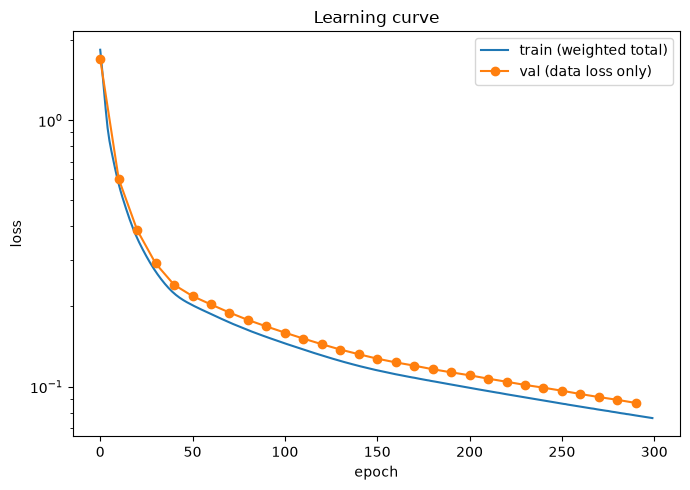

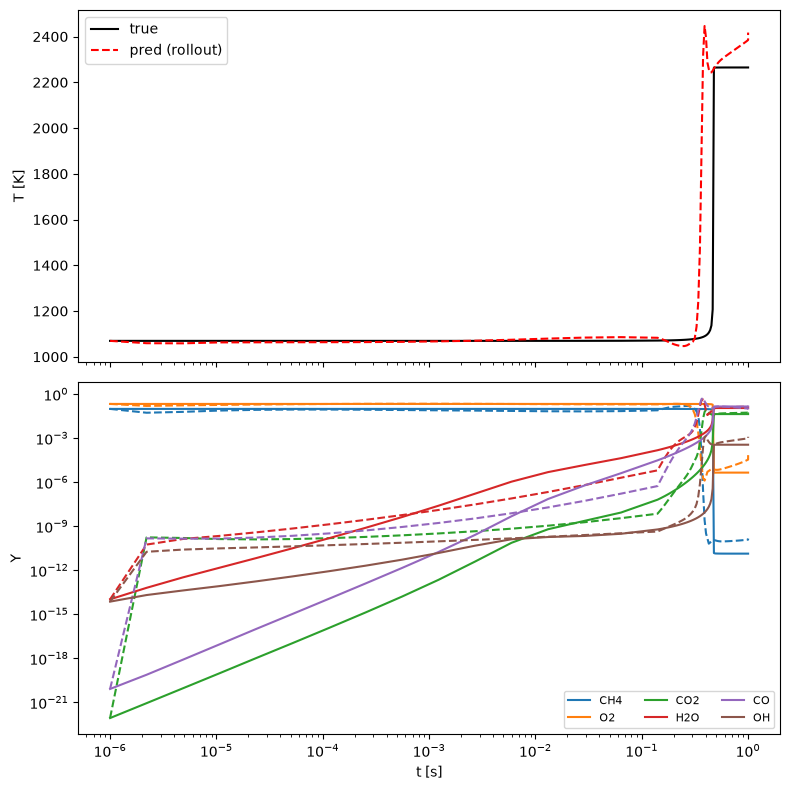

In [16]:
fig, axes = plt.subplots(1, 1, figsize=(7, 5))
axes.plot(train_losses, label="train (weighted total)")
axes.plot(val_epochs, val_losses, label="val (data loss only)", marker="o")
axes.set_xlabel("epoch")
axes.set_ylabel("loss")
axes.set_yscale("log")
axes.legend()
axes.set_title("Learning curve")
plt.tight_layout()
plt.show()

# ---- Rollout on one held-out trajectory ----
traj_id = list(val_ids)[0]
traj = df[df["traj_idx"] == traj_id].sort_values("t").reset_index(drop=True)

T0_val = torch.tensor([traj.loc[0, "T0"]], dtype=torch.float32, device=device)
P_val = torch.tensor([traj.loc[0, "P"]], dtype=torch.float32, device=device)
t_end_val = torch.tensor([N_IDT * traj.loc[0, "t_ign"]], dtype=torch.float32, device=device)

T_cur = torch.tensor([traj.loc[0, "T"]], dtype=torch.float32, device=device)
Y_cur = torch.tensor([[traj.loc[0, f"Y_{s}"] for s in species_cols]], dtype=torch.float32, device=device)
t_arr = traj["t"].to_numpy()

T_rollout = [T_cur.item()]
Y_rollout = [Y_cur.cpu().numpy()[0]]

with torch.no_grad():
    for i in range(len(t_arr) - 1):
        dt = torch.tensor([t_arr[i + 1] - t_arr[i]], dtype=torch.float32, device=device)
        T_cur, Y_cur, _ = model(T_cur, Y_cur, T0_val, P_val, dt, t_end_val)
        T_rollout.append(T_cur.item())
        Y_rollout.append(Y_cur.cpu().numpy()[0])

T_rollout = np.array(T_rollout)
Y_rollout = np.array(Y_rollout)
Y_true = traj[[f"Y_{s}" for s in species_cols]].to_numpy()

fig2, axes2 = plt.subplots(2, 1, figsize=(8, 8), sharex=True)
axes2[0].plot(t_arr, traj["T"], label="true", color="black")
axes2[0].plot(t_arr, T_rollout, label="pred (rollout)", color="red", linestyle="--")
axes2[0].set_ylabel("T [K]")
axes2[0].set_xscale("log")
axes2[0].legend()

species_to_show = [s for s in ["CH4", "O2", "CO2", "H2O", "CO", "OH"] if s in species_cols][:6]
for i, s in enumerate(species_to_show):
    j = species_cols.index(s)
    axes2[1].plot(t_arr, Y_true[:, j], color=f"C{i}", label=s)
    axes2[1].plot(t_arr, Y_rollout[:, j], color=f"C{i}", linestyle="--")
axes2[1].set_xlabel("t [s]")
axes2[1].set_ylabel("Y")
axes2[1].set_yscale("log")
axes2[1].set_xscale("log")
axes2[1].legend(fontsize=8, ncol=3)

plt.tight_layout()
plt.show()

# Final errors

In [17]:
def rollout_trajectory(traj):
    T0_v = torch.tensor([traj.loc[0, "T0"]], dtype=torch.float32, device=device)
    P_v = torch.tensor([traj.loc[0, "P"]], dtype=torch.float32, device=device)
    t_end_v = torch.tensor([N_IDT * traj.loc[0, "t_ign"]], dtype=torch.float32, device=device)

    T_cur = torch.tensor([traj.loc[0, "T"]], dtype=torch.float32, device=device)
    Y_cur = torch.tensor([[traj.loc[0, f"Y_{s}"] for s in species_cols]], dtype=torch.float32, device=device)
    t_arr = traj["t"].to_numpy()

    with torch.no_grad():
        for i in range(len(t_arr) - 1):
            dt = torch.tensor([t_arr[i + 1] - t_arr[i]], dtype=torch.float32, device=device)
            T_cur, Y_cur, _ = model(T_cur, Y_cur, T0_v, P_v, dt, t_end_v)

    return T_cur.item(), Y_cur.cpu().numpy()[0]


def rel_l2(pred, true, eps=1e-12):
    denom = np.linalg.norm(true)
    if denom < eps:
        return np.nan
    return np.linalg.norm(pred - true) / denom


T_final_pred, T_final_true = [], []
Y_final_pred, Y_final_true = [], []

for traj_id in val_ids:
    traj = df[df["traj_idx"] == traj_id].sort_values("t").reset_index(drop=True)
    T_pred, Y_pred = rollout_trajectory(traj)
    T_final_pred.append(T_pred)
    T_final_true.append(traj.loc[len(traj) - 1, "T"])
    Y_final_pred.append(Y_pred)
    Y_final_true.append(traj.loc[len(traj) - 1, [f"Y_{s}" for s in species_cols]].to_numpy(dtype=float))

T_final_pred, T_final_true = np.array(T_final_pred), np.array(T_final_true)
Y_final_pred, Y_final_true = np.array(Y_final_pred), np.array(Y_final_true)

results = [{"quantity": "T", "rel_l2_error_pct": rel_l2(T_final_pred, T_final_true) * 100}]
for i, s in enumerate(species_cols):
    results.append({"quantity": s, "rel_l2_error_pct": rel_l2(Y_final_pred[:, i], Y_final_true[:, i]) * 100})

error_df = pd.DataFrame(results).sort_values("rel_l2_error_pct", ascending=False, na_position="last")
error_df["rel_l2_error_pct"] = error_df["rel_l2_error_pct"].round(2)
error_df.to_csv("../data/processed/final_state_errors.csv", index=False)

display_df = error_df.copy()
display_df["rel_l2_error_pct"] = display_df["rel_l2_error_pct"].apply(
    lambda x: f"{x:.2f}%" if pd.notna(x) else "N/A (negligible true value)"
)
print(display_df.to_string(index=False))
print("\nSaved to data/processed/final_state_errors.csv")

quantity            rel_l2_error_pct
     CH4               593860663.75%
     CH3                  465675.19%
   CH2CO                  160746.98%
    HCNO                  123871.83%
      CH                  119807.01%
    CH2O                  113896.40%
   CH2OH                   69475.25%
     C2H                   65689.75%
       C                   36423.27%
    HCCO                   29223.78%
   HCCOH                   22097.06%
    H2CN                   16313.75%
     CH2                   15648.77%
    C2H2                     237.75%
      O2                     158.71%
    HNCO                     140.95%
      CN                     136.36%
    HOCN                     121.04%
     HCN                     111.11%
     NH3                     109.26%
     NO2                      85.76%
    H2O2                      80.67%
       N                      71.84%
     N2O                      65.46%
      NH                      64.18%
     NNH                      62.89%
 